In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, classification_report
)

df = pd.read_csv(
    "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
)

print("Datheon Internship | Task 1")
print("Iris Flower Classification")
print("Dataset shape:", df.shape)
display(df.head())

Datheon Internship | Task 1
Iris Flower Classification
Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset information:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species distribution:


,count
species,
setosa,50
versicolor,50
virginica,50



Missing values:


,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


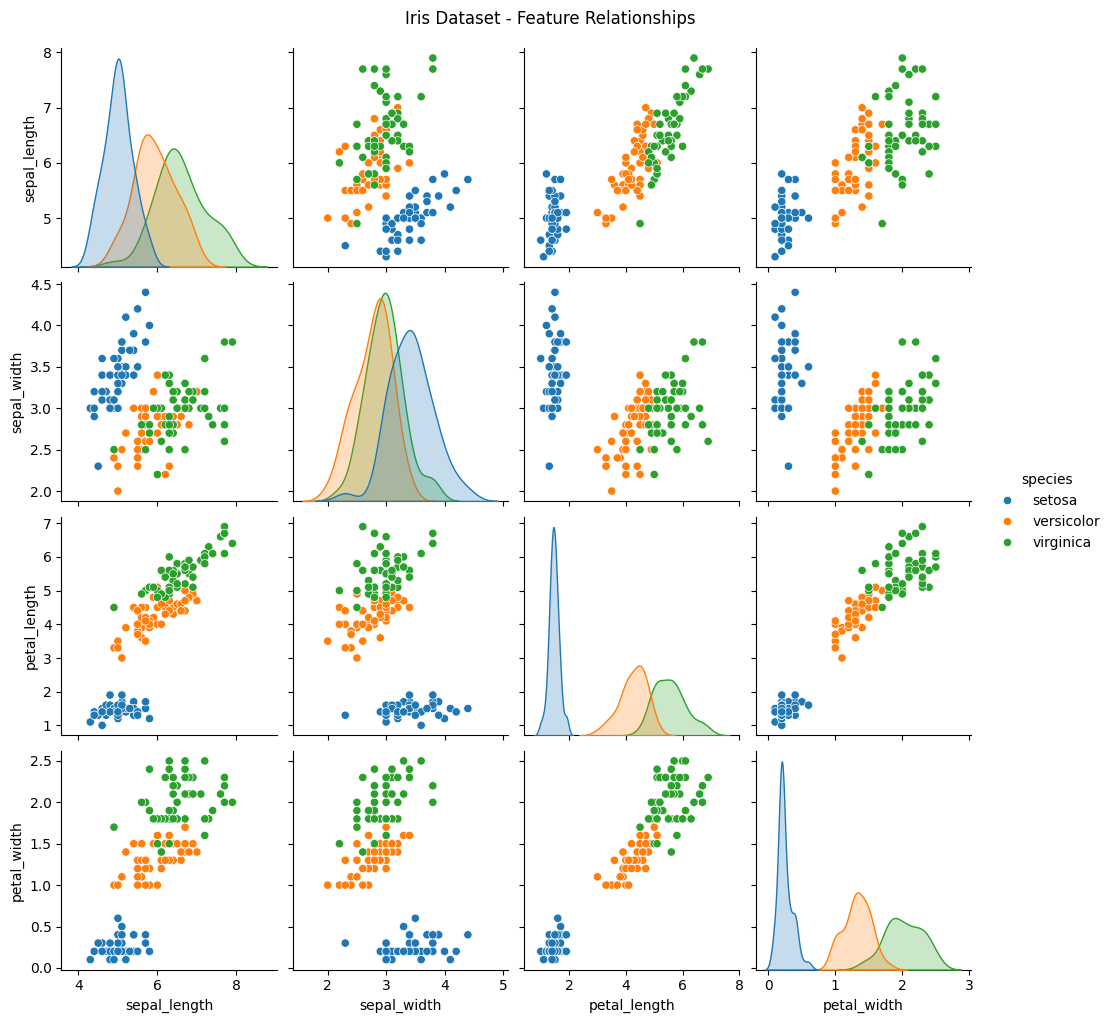

In [2]:
print("Dataset information:")
display(df.describe())

print("\nSpecies distribution:")
display(df["species"].value_counts())

print("\nMissing values:")
display(df.isnull().sum())

sns.pairplot(df, hue="species")
plt.suptitle("Iris Dataset - Feature Relationships", y=1.02)
plt.show()

In [5]:
X = df.drop(columns=["species"])
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="macro"
        )
    })

    print(f"\n{name}")
    print(classification_report(y_test, predictions))

results_df = pd.DataFrame(results)
display(results_df.round(4))


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


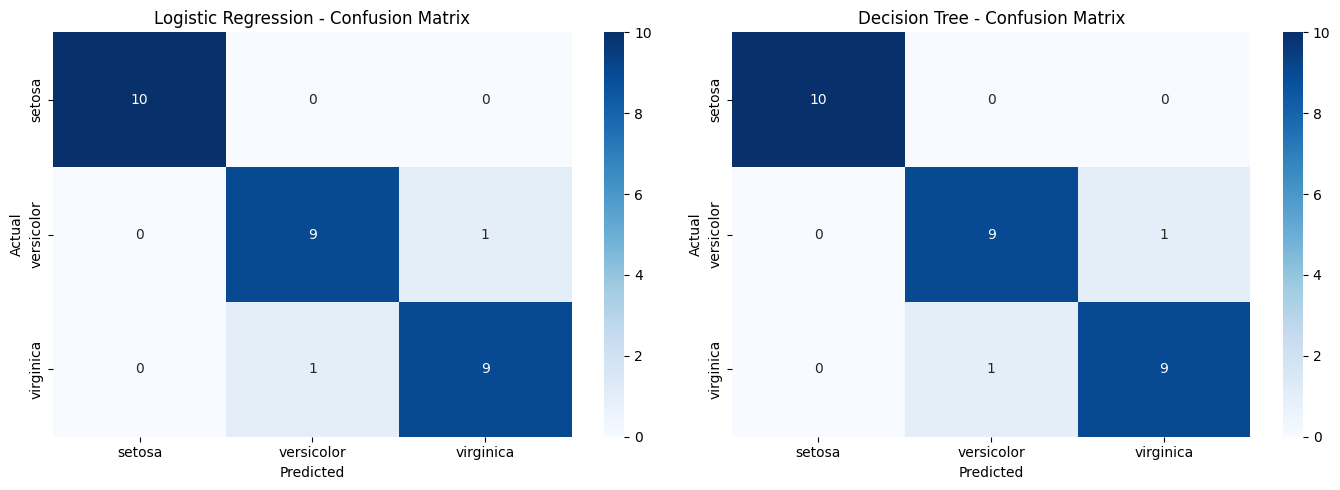

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, models.items()):
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test, predictions,
        labels=model.classes_
    )

    sns.heatmap(
        cm, annot=True, fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=ax
    )

    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

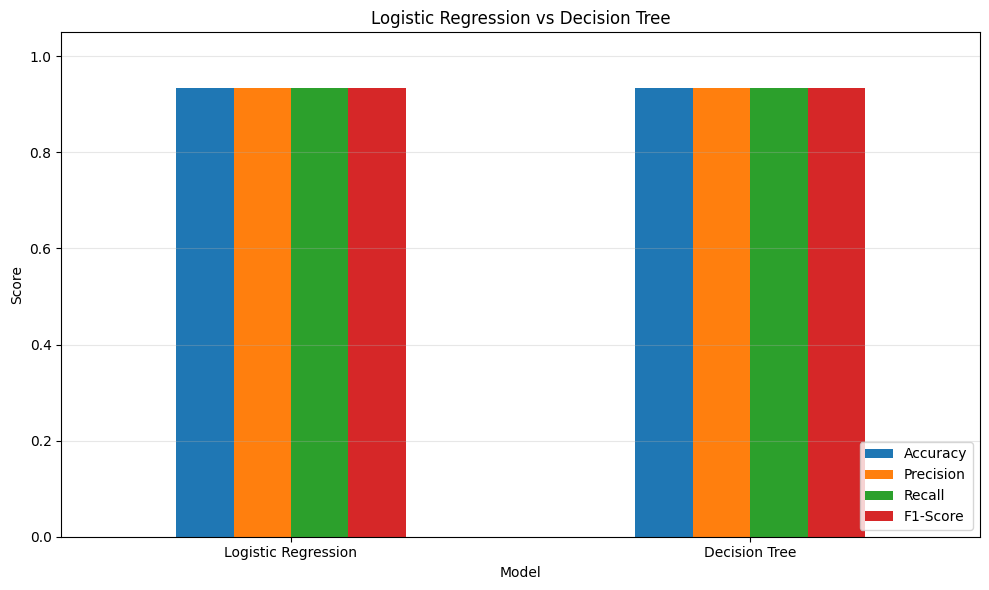

In [7]:
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

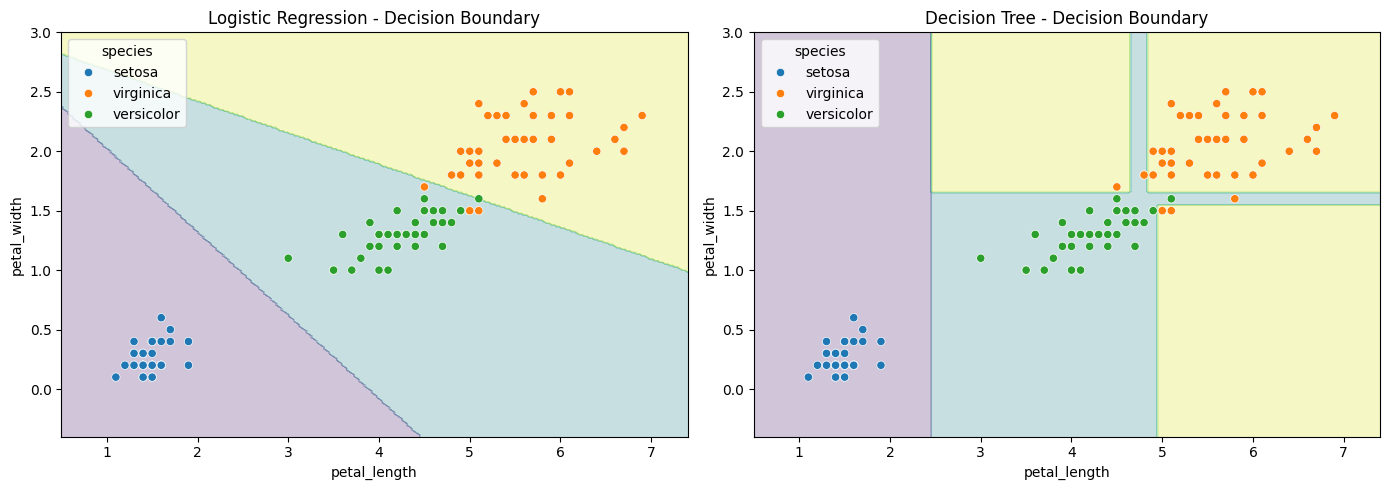

In [8]:
features = ["petal_length", "petal_width"]
X2 = df[features]
y2 = df["species"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2,
    test_size=0.20,
    random_state=42,
    stratify=y2
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X2_train, y2_train)

    x_min, x_max = X2["petal_length"].min() - 0.5, X2["petal_length"].max() + 0.5
    y_min, y_max = X2["petal_width"].min() - 0.5, X2["petal_width"].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = pd.DataFrame({
        "petal_length": xx.ravel(),
        "petal_width": yy.ravel()
    })

    classes = list(model.classes_)
    Z = pd.Categorical(
        model.predict(grid),
        categories=classes
    ).codes.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")

    sns.scatterplot(
        data=pd.DataFrame({
            "petal_length": X2_train["petal_length"],
            "petal_width": X2_train["petal_width"],
            "species": y2_train
        }),
        x="petal_length",
        y="petal_width",
        hue="species",
        ax=ax
    )

    ax.set_title(f"{name} - Decision Boundary")

plt.tight_layout()
plt.show()